# Lab 01 · 합성곱의 귀납적 편향과, 2차원 장난감 데이터로 만드는 디퓨전 모델

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 부 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| A-1 | 합성곱을 NumPy로 직접 계산 | CS231n 강의노트, AlexNet (2012) |
| A-2 | 파라미터가 훨씬 적은 CNN이 MLP와 비슷한 정확도를 내는 이유 | VGG (2014), ResNet (2015) |
| A-3 | 이미지를 1픽셀 밀었을 때 MLP와 CNN의 차이 (등변성 vs 불변성) | ViT (2020)의 "귀납적 편향" 논의 |
| B-1 | 데이터에 잡음을 조금씩 섞는 정방향 과정 | Ho et al. (2020) *DDPM* |
| B-2 | "섞인 잡음을 맞히는" 신경망 학습 (논문 Algorithm 1) | DDPM, *Step-by-Step Diffusion* (2024) |
| B-3 | 잡음에서 시작해 한 단계씩 되돌리는 샘플링 (Algorithm 2) | DDPM |

**소요 시간**: 90분 · **패키지**: numpy, matplotlib, scikit-learn, torch (CPU 1~2분)

In [1]:
import numpy as np, matplotlib.pyplot as plt, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits, make_moons
from sklearn.model_selection import train_test_split
plt.rcParams.update({"figure.dpi": 80})
torch.manual_seed(0); rng = np.random.default_rng(0)

# A부. 합성곱 신경망

## A-1. 합성곱을 손으로

합성곱 층은 작은 필터(예: 3×3)를 이미지 위에서 한 칸씩 옮기며 **같은 가중치로** 내적을 계산합니다. 세로 경계를 찾는 필터를 숫자 이미지에 적용해 봅니다.

✍️ **예측**: 8×8 이미지에 3×3 필터를 패딩 없이 적용하면 출력 크기는?

출력 크기: (6, 6) | PyTorch F.conv2d 와 최대 차이: 0.0


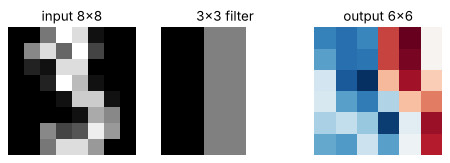

In [2]:
digits = load_digits()
img = digits.images[3] / 16.0                                  # 8x8 숫자 '3'
kernel = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=float)   # 왼쪽이 어둡고 오른쪽이 밝으면 큰 값

def conv2d(image, k):
    H, W = image.shape; kh, kw = k.shape
    out = np.zeros((H - kh + 1, W - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(image[i:i + kh, j:j + kw] * k)   # 겹친 부분의 원소별 곱의 합
    return out

mine = conv2d(img, kernel)
ref = F.conv2d(torch.tensor(img)[None, None], torch.tensor(kernel)[None, None])[0, 0].numpy()
print("출력 크기:", mine.shape, "| PyTorch F.conv2d 와 최대 차이:", np.abs(mine - ref).max())
fig, axes = plt.subplots(1, 3, figsize=(7, 2.4))
for ax, m, t in zip(axes, [img, kernel, mine], ["input 8x8", "3x3 filter", "output 6x6"]):
    ax.imshow(m, cmap="gray" if t != "output 6x6" else "RdBu"); ax.set_title(t); ax.axis("off")
plt.show()

## A-2. MLP와 CNN 비교

- MLP는 256개 픽셀(여백 포함 16×16)을 **순서 없는 숫자 256개**로 봅니다. 픽셀 위치마다 가중치가 따로 있습니다.
- CNN은 "가까운 픽셀끼리 의미가 있다(국소성)", "같은 무늬는 어디에 있어도 같은 무늬다(가중치 공유)"라는 가정을 구조에 넣었습니다. 이런 가정을 **귀납적 편향(inductive bias)** 이라고 합니다.

✍️ **예측**: 아래 CNN의 파라미터 수는 MLP의 몇 분의 일일까요? 정확도는?

In [3]:
X = torch.tensor(digits.images / 16.0, dtype=torch.float32)[:, None]            # (N, 1, 8, 8)
X = F.pad(X, (4, 4, 4, 4))                                                      # 사방에 4픽셀 여백 → (N, 1, 16, 16). 밀어도 글자가 잘리지 않게
y = torch.tensor(digits.target)
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.3, random_state=0, stratify=digits.target)
X_tr, X_te, y_tr, y_te = X[idx_tr], X[idx_te], y[idx_tr], y[idx_te]

def make_mlp(): return nn.Sequential(nn.Flatten(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
def make_cnn(): return nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),       # 16x16 → 8x8
                                     nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # 8x8 → 4x4
                                     nn.Flatten(), nn.Linear(16 * 4 * 4, 10))

def make_cnn_gap(): return nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
                                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10))               # 위치 정보를 평균으로 지운다 (global average pooling)

def train(model, X, y, epochs=40, seed=0):
    torch.manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            b = perm[i:i + 64]; loss = F.cross_entropy(model(X[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

@torch.no_grad()
def acc(model, X, y): return (model(X).argmax(1) == y).float().mean().item()

torch.manual_seed(0); mlp = train(make_mlp(), X_tr, y_tr)
torch.manual_seed(0); cnn = train(make_cnn(), X_tr, y_tr)
torch.manual_seed(0); cnn_gap = train(make_cnn_gap(), X_tr, y_tr, epochs=60)
count = lambda m: sum(p.numel() for p in m.parameters())
models = {"MLP": mlp, "CNN (flatten)": cnn, "CNN (global avg pool)": cnn_gap}
for name, m in models.items(): print(f"{name:22s}: 파라미터 {count(m):5d}개, test 정확도 {acc(m, X_te, y_te):.3f}")

MLP                   : 파라미터 34186개, test 정확도 0.981
CNN (flatten)         : 파라미터  3818개, test 정확도 0.974
CNN (global avg pool) : 파라미터 19466개, test 정확도 0.906


## A-3. 이미지를 1픽셀 밀면?

학습은 가운데 정렬된 이미지로만 했습니다. 테스트 이미지를 오른쪽·아래로 1~2픽셀 밀어 다시 평가합니다(여백이 있어 글자는 잘리지 않습니다). 사람 눈에는 같은 숫자입니다.

✍️ **예측**: 세 모델 중 어느 쪽 정확도가 가장 많이, 가장 적게 떨어질까요?

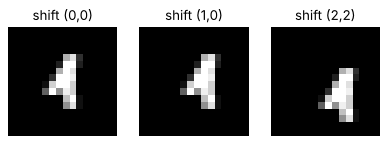

shift (0,0):  MLP 0.981   CNN (flatten) 0.974   CNN (global avg pool) 0.906


shift (1,0):  MLP 0.481   CNN (flatten) 0.528   CNN (global avg pool) 0.906
shift (0,1):  MLP 0.419   CNN (flatten) 0.424   CNN (global avg pool) 0.906
shift (2,2):  MLP 0.057   CNN (flatten) 0.102   CNN (global avg pool) 0.906


In [4]:
def shift(X, dx, dy):
    out = torch.zeros_like(X)
    H, W = X.shape[-2:]
    out[..., max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)] = X[..., max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)]
    return out

fig, axes = plt.subplots(1, 3, figsize=(6, 2.2))
for ax, (dx, dy) in zip(axes, [(0, 0), (1, 0), (2, 2)]):
    ax.imshow(shift(X_te[:1], dx, dy)[0, 0], cmap="gray"); ax.set_title(f"shift ({dx},{dy})"); ax.axis("off")
plt.show()
for dx, dy in [(0, 0), (1, 0), (0, 1), (2, 2)]:
    Xs = shift(X_te, dx, dy)
    print(f"shift ({dx},{dy}):  " + "   ".join(f"{name} {acc(m, Xs, y_te):.3f}" for name, m in models.items()))

- 원본 이미지에서 MLP와 보통의 CNN(`flatten` 뒤에 Linear)은 정확도가 거의 같습니다. CNN의 파라미터는 MLP의 약 1/9입니다.
- 1~2픽셀 밀면 **MLP와 보통의 CNN 모두 크게 무너집니다.** MLP는 "이 픽셀 위치에 획이 있으면 3"처럼 위치를 통째로 외웠습니다. CNN의 합성곱은 "입력이 밀리면 특징 지도도 같이 밀리는" **등변성(equivariance)** 만 가질 뿐이고, 마지막 Linear 층이 위치별 가중치를 다시 쓰기 때문에 조금 나을 뿐입니다.
- 특징 지도를 **전체 평균**(global average pooling)한 CNN은 밀어도 정확도가 **완전히 같습니다.** 등변인 특징을 평균하면 **불변성(invariance)** 이 됩니다. ResNet이 마지막에 global average pooling을 쓰는 것을 논문의 구조 표에서 확인해 보세요.
- 대신 그 모델은 원본 정확도가 더 낮습니다. 위치 정보를 버렸으니 "획이 어디에 있는가"를 쓸 수 없습니다. **불변성은 공짜가 아니라 정보와 맞바꾸는 것**입니다.
- **ViT 논문이 말하는 것**: Transformer에는 이런 가정이 거의 없어서, 데이터가 적으면 CNN보다 못하고 데이터가 아주 많으면 가정 없이도 더 잘 배웁니다. 논문의 "사전학습 데이터 크기별 성능" 그림을 이 실험과 연결해 읽어 보세요.

# B부. 디퓨전 모델을 2차원에서

이미지는 수만 차원의 점입니다. 같은 알고리즘을 **2차원 점**에 적용하면 모든 과정을 그림으로 볼 수 있습니다. 데이터는 초승달 두 개 모양의 점들입니다.

## B-1. 정방향 과정: 잡음을 조금씩 섞기

$T$ 단계에 걸쳐 데이터에 가우시안 잡음을 섞습니다. 논문의 핵심 편의: 중간 단계를 거치지 않고 **임의의 시점 $t$ 의 상태를 한 번에** 만들 수 있습니다.

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon,\qquad \varepsilon\sim\mathcal N(0,I),\quad \bar\alpha_t=\prod_{s\le t}(1-\beta_s)$$

✍️ **예측**: $t$ 가 커질수록 $\bar\alpha_t$ 는 어떻게 되고, $x_T$ 는 어떤 분포가 될까요?

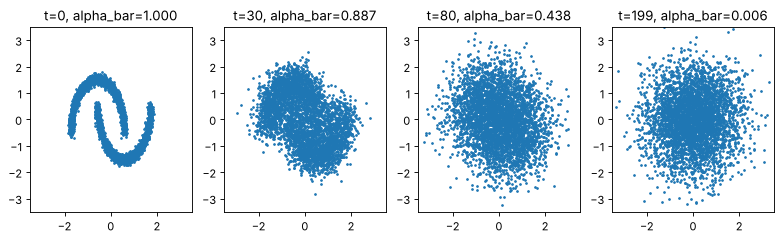

In [5]:
data, _ = make_moons(n_samples=4000, noise=0.05, random_state=0)
data = torch.tensor((data - data.mean(0)) / data.std(0), dtype=torch.float32)

T = 200
betas = torch.linspace(1e-4, 0.05, T)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

def q_sample(x0, t, eps):                                   # t: 0 ~ T-1 의 정수 텐서
    ab = alpha_bar[t][:, None]
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, t in zip(axes, [0, 30, 80, 199]):
    xt = q_sample(data, torch.full((len(data),), t), torch.randn_like(data))
    ax.scatter(xt[:, 0], xt[:, 1], s=2); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_title(f"t={t}, alpha_bar={alpha_bar[t]:.3f}")
plt.show()

## B-2. 학습: 섞인 잡음을 맞혀라 (DDPM Algorithm 1)

신경망 $\varepsilon_\theta(x_t,t)$ 에게 "잡음이 섞인 점과 시점을 줄 테니, **섞인 잡음**이 무엇이었는지 맞혀 봐"라고 시킵니다. 손실은 단순한 MSE입니다.

$$L=\mathbb E_{x_0,t,\varepsilon}\big[\lVert\varepsilon-\varepsilon_\theta(x_t,t)\rVert^2\big]$$

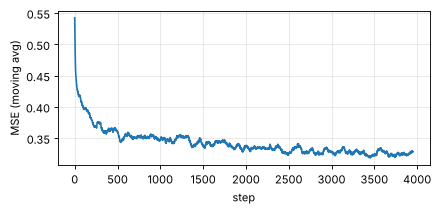

마지막 500스텝 평균 손실 = 0.326 (1.0이면 아무것도 못 맞히는 수준)


In [6]:
class NoisePredictor(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 + 16, hidden), nn.SiLU(), nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 2))
    def time_embedding(self, t):                              # 시점 t를 sin/cos 16차원으로 (Transformer의 위치 인코딩과 같은 발상)
        freqs = torch.exp(torch.linspace(0, np.log(1000), 8))
        angles = (t[:, None].float() / T) * freqs[None, :] * 2 * np.pi
        return torch.cat([angles.sin(), angles.cos()], dim=1)
    def forward(self, x, t):
        return self.net(torch.cat([x, self.time_embedding(t)], dim=1))

torch.manual_seed(0)
model = NoisePredictor(); opt = torch.optim.Adam(model.parameters(), lr=2e-3); losses = []
for step in range(4000):
    x0 = data[torch.randint(0, len(data), (512,))]            # 1) 데이터에서 뽑고
    t = torch.randint(0, T, (512,))                           # 2) 시점을 무작위로 고르고
    eps = torch.randn_like(x0)                                # 3) 잡음을 만들어
    loss = F.mse_loss(model(q_sample(x0, t, eps), t), eps)    # 4) 섞은 뒤, 그 잡음을 맞히게 한다
    opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
plt.figure(figsize=(6, 2.5)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid")); plt.xlabel("step"); plt.ylabel("MSE (moving avg)"); plt.grid(alpha=0.3); plt.show()
print("마지막 500스텝 평균 손실 =", round(float(np.mean(losses[-500:])), 3), "(1.0이면 아무것도 못 맞히는 수준)")

손실이 0까지 내려가지 않는 것이 정상입니다. 잡음이 많이 섞인 시점($t$ 가 큼)에서는 어떤 잡음이 섞였는지 정확히 알 수 없기 때문입니다.

## B-3. 샘플링: 잡음에서 시작해 되돌리기 (DDPM Algorithm 2)

순수한 잡음 $x_T\sim\mathcal N(0,I)$ 에서 시작해, 예측한 잡음을 조금 빼고 약간의 새 잡음을 더하는 것을 $T$ 번 반복합니다.

$$x_{t-1}=\frac1{\sqrt{\alpha_t}}\Big(x_t-\frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t,t)\Big)+\sigma_t z,\qquad \sigma_t=\sqrt{\beta_t}$$

✍️ **예측**: 학습 때 모델은 "초승달 모양을 그려라"는 말을 들은 적이 없습니다. 그래도 초승달이 나올까요?

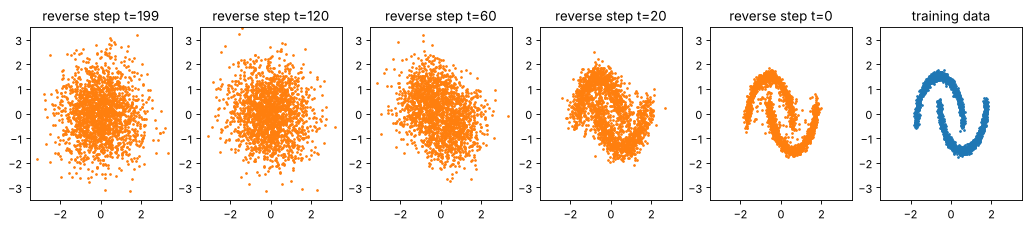

가장 가까운 학습 데이터까지의 평균 거리 — 생성한 점: 0.032 | 실제 데이터(다른 절반): 0.020 | 순수 잡음: 0.258


In [7]:
@torch.no_grad()
def sample(model, n=2000, seed=0, keep=(199, 120, 60, 20, 0)):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 2, generator=g); snapshots = {}
    for t in reversed(range(T)):
        eps_hat = model(x, torch.full((n,), t))
        x = (x - (1 - alphas[t]) / (1 - alpha_bar[t]).sqrt() * eps_hat) / alphas[t].sqrt()
        if t > 0: x = x + betas[t].sqrt() * torch.randn(n, 2, generator=g)      # 마지막 단계에는 잡음을 더하지 않는다
        if t in keep: snapshots[t] = x.clone()
    return x, snapshots

generated, snaps = sample(model)
fig, axes = plt.subplots(1, 6, figsize=(16, 2.8))
for ax, t in zip(axes, [199, 120, 60, 20, 0]):
    ax.scatter(snaps[t][:, 0], snaps[t][:, 1], s=2, c="tab:orange"); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_title(f"reverse step t={t}")
axes[-1].scatter(data[:2000, 0], data[:2000, 1], s=2); axes[-1].set_xlim(-3.5, 3.5); axes[-1].set_ylim(-3.5, 3.5); axes[-1].set_title("training data")
plt.show()
nearest = lambda a, b: torch.cdist(a, b).min(dim=1).values.mean().item()
print(f"가장 가까운 학습 데이터까지의 평균 거리 — 생성한 점: {nearest(generated, data[2000:]):.3f} | 실제 데이터(다른 절반): {nearest(data[:2000], data[2000:]):.3f} | 순수 잡음: {nearest(torch.randn(2000, 2), data[2000:]):.3f}")

잡음 덩어리가 단계마다 조금씩 정리되어 **학습 데이터와 같은 모양의 새 점들**이 됩니다. 모델은 모양을 직접 배운 적이 없고 "잡음 맞히기"만 배웠습니다. 각 지점에서 "데이터가 있는 쪽"을 가리키는 방향을 배운 셈이고, 그 방향을 따라 조금씩 걸어가면 데이터 분포에 도착합니다.

이미지 생성 모델은 여기서 (1) 2차원 점 → 이미지(또는 잠재 벡터), (2) 작은 MLP → U-Net이나 Transformer(DiT), (3) 조건 없음 → 텍스트 조건 + guidance 로 바뀐 것입니다. 뼈대는 위의 세 셀입니다.

---
## 직접 해보기

1. **(시점 정보 제거)** `NoisePredictor` 가 시점 $t$ 를 보지 못하게(임베딩을 0으로) 하고 다시 학습·샘플링하면 어떻게 될까요? 먼저 예측하고 확인하세요.
2. **(단계 수)** 학습된 모델로 샘플링 단계를 건너뛰면(예: 10단계마다 한 번만 갱신) 결과가 어떻게 되나요? 왜 빠른 샘플러(DDIM 등)가 연구되는지 생각해 보세요.
3. **(증강)** A부의 MLP를 "무작위로 0~2픽셀 민 이미지"로 학습하면 A-3의 결과가 어떻게 바뀌나요? 구조에 가정을 넣는 것과 데이터로 가르치는 것의 차이를 한 문장으로 정리해 보세요.

In [8]:
# TODO 1: 시점 정보 없이 학습

# TODO 3: 이동 증강으로 학습한 MLP

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

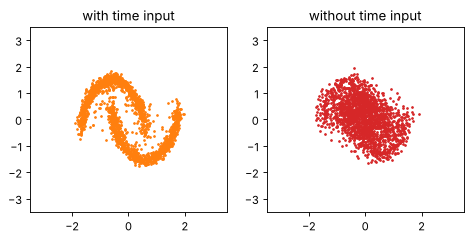

마지막 500스텝 평균 손실  시점 입력 있음: 0.326   없음: 0.428


In [9]:
# 1. 시점 정보를 지운 모델
class NoTime(NoisePredictor):
    def time_embedding(self, t): return torch.zeros(len(t), 16)

torch.manual_seed(0); blind = NoTime(); opt = torch.optim.Adam(blind.parameters(), lr=2e-3); blind_losses = []
for step in range(4000):
    x0 = data[torch.randint(0, len(data), (512,))]; t = torch.randint(0, T, (512,)); eps = torch.randn_like(x0)
    loss = F.mse_loss(blind(q_sample(x0, t, eps), t), eps); opt.zero_grad(); loss.backward(); opt.step(); blind_losses.append(loss.item())
gen_blind, _ = sample(blind)
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].scatter(generated[:, 0], generated[:, 1], s=2, c="tab:orange"); axes[0].set_title("with time input")
axes[1].scatter(gen_blind[:, 0], gen_blind[:, 1], s=2, c="tab:red"); axes[1].set_title("without time input")
for ax in axes: ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
plt.show()
print(f"마지막 500스텝 평균 손실  시점 입력 있음: {np.mean(losses[-500:]):.3f}   없음: {np.mean(blind_losses[-500:]):.3f}")

In [10]:
# 3. 이동 증강으로 학습한 MLP
def augment(X):
    out = X.clone()
    for i in range(len(X)):
        dx, dy = np.random.randint(0, 3), np.random.randint(0, 3)
        out[i:i + 1] = shift(X[i:i + 1], dx, dy)
    return out

np.random.seed(0); torch.manual_seed(0)
X_aug = torch.cat([augment(X_tr) for _ in range(4)]); y_aug = y_tr.repeat(4)
mlp_aug = train(make_mlp(), X_aug, y_aug, epochs=15)
for dx, dy in [(0, 0), (1, 0), (0, 1), (2, 2)]:
    Xs = shift(X_te, dx, dy)
    print(f"shift ({dx},{dy}):  MLP {acc(mlp, Xs, y_te):.3f}   MLP+증강 {acc(mlp_aug, Xs, y_te):.3f}   CNN(GAP) {acc(cnn_gap, Xs, y_te):.3f}")

shift (0,0):  MLP 0.981   MLP+증강 0.935   CNN(GAP) 0.906
shift (1,0):  MLP 0.481   MLP+증강 0.939   CNN(GAP) 0.906
shift (0,1):  MLP 0.419   MLP+증강 0.954   CNN(GAP) 0.906
shift (2,2):  MLP 0.057   MLP+증강 0.931   CNN(GAP) 0.906


**해석**
- 1번: 시점을 모르면 "지금 잡음이 얼마나 섞였는지"를 점의 위치만으로 추측해야 해서 손실이 더 높고, 생성 결과가 덜 선명해집니다. 시점 조건이 왜 필요한지 보여 줍니다. (이 2차원 예제에서는 위치만으로도 어느 정도 추측이 되어 차이가 작게 나올 수 있습니다.)
- 3번: 증강으로 "밀려도 같은 숫자"를 **데이터로** 가르치면 MLP도 강건해지고, 위치 정보도 계속 쓸 수 있어 정확도가 높게 유지됩니다. global average pooling을 쓴 CNN은 같은 성질을 **구조로** 갖고 있어 그런 데이터 없이도 됩니다. ViT가 대량의 데이터·증강을 필요로 하는 이유와 같은 이야기입니다.

---
## 논문으로 돌아가기

| 방금 한 것 | 논문에서 확인할 곳 |
|---|---|
| A-2, A-3 | ViT 논문의 귀납적 편향 논의와 "사전학습 데이터 크기에 따른 성능" 그림. ConvNeXt 논문의 "ResNet을 한 단계씩 현대화" 그림 |
| B-1 `q_sample` | DDPM 논문의 정방향 과정 식(임의 시점을 한 번에 뽑는 닫힌 형태) |
| B-2 학습 루프 | DDPM **Algorithm 1** (4줄). 손실이 왜 "단순화된" 목적함수인지 설명하는 절 |
| B-3 `sample` | DDPM **Algorithm 2** (6줄). $\sigma_t$ 의 선택에 대한 설명 |
| 전체 | *Step-by-Step Diffusion* 튜토리얼의 앞부분이 이 2차원 실험과 같은 관점으로 설명한다 |

## 기억 점검

1. 합성곱 층이 MLP보다 파라미터가 적은 이유 두 가지는?
2. 귀납적 편향이란? CNN과 ViT는 이 점에서 어떻게 다른가?
3. 디퓨전의 정방향 과정과 역방향 과정은 각각 무엇을 하나? 학습되는 것은 어느 쪽인가?
4. DDPM의 신경망은 무엇을 입력받아 무엇을 예측하나? 손실은?
5. 샘플링에 단계가 많이 필요한 이유는?

<details><summary>답 확인</summary>

1. 작은 필터만 쓰고(국소 연결), 같은 필터를 모든 위치에서 재사용한다(가중치 공유).
2. 모델 구조에 미리 넣어 둔 데이터에 대한 가정. CNN은 국소성·이동 등변성을 구조로 갖고, ViT는 그런 가정이 약해 데이터가 많이 필요하지만 많으면 더 잘 배운다.
3. 정방향: 데이터에 잡음을 점점 섞어 순수 잡음으로(고정, 학습 없음). 역방향: 잡음에서 데이터로 한 단계씩 되돌림(신경망이 학습).
4. 잡음 섞인 $x_t$ 와 시점 $t$ 를 받아 섞인 잡음 $\varepsilon$ 을 예측. 손실은 실제 잡음과의 MSE.
5. 한 단계에서 되돌리는 양이 작아야 "가우시안으로 근사"가 성립하기 때문. 단계를 줄이면 품질이 떨어져, 적은 단계로 샘플링하는 방법이 따로 연구된다.
</details>